### Credit Card Customer dataset EDA and Clustering

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
import kagglehub

path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")

print("Path to dataset files:", path)

100%|██████████| 379k/379k [00:00<00:00, 81.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshigoyal7/credit-card-customers/versions/1


In [53]:
df = pd.read_csv(path + "/BankChurners.csv")
print("\nFirst 5 rows:")
print(df.head())
print("\nSummary description:")
print(df.describe())
print("\nInfo about the variables:")
print(df.info())


First 5 rows:
   CLIENTNUM     Attrition_Flag  Customer_Age Gender  Dependent_count  \
0  768805383  Existing Customer            45      M                3   
1  818770008  Existing Customer            49      F                5   
2  713982108  Existing Customer            51      M                3   
3  769911858  Existing Customer            40      F                4   
4  709106358  Existing Customer            40      M                3   

  Education_Level Marital_Status Income_Category Card_Category  \
0     High School        Married     $60K - $80K          Blue   
1        Graduate         Single  Less than $40K          Blue   
2        Graduate        Married    $80K - $120K          Blue   
3     High School        Unknown  Less than $40K          Blue   
4      Uneducated        Married     $60K - $80K          Blue   

   Months_on_book  ...  Credit_Limit  Total_Revolving_Bal  Avg_Open_To_Buy  \
0              39  ...       12691.0                  777          1191

### Simple EDA

## Remove non informative columns

In [54]:
columns_to_remove = ['CLIENTNUM',
                     'Attrition_Flag',
                     'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
                     'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
df = df.drop(columns=columns_to_remove)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_Age              10127 non-null  int64  
 1   Gender                    10127 non-null  object 
 2   Dependent_count           10127 non-null  int64  
 3   Education_Level           10127 non-null  object 
 4   Marital_Status            10127 non-null  object 
 5   Income_Category           10127 non-null  object 
 6   Card_Category             10127 non-null  object 
 7   Months_on_book            10127 non-null  int64  
 8   Total_Relationship_Count  10127 non-null  int64  
 9   Months_Inactive_12_mon    10127 non-null  int64  
 10  Contacts_Count_12_mon     10127 non-null  int64  
 11  Credit_Limit              10127 non-null  float64
 12  Total_Revolving_Bal       10127 non-null  int64  
 13  Avg_Open_To_Buy           10127 non-null  float64
 14  Total_

### Handling Categorical Features using One-Hot encoding

In [58]:
categorical_cols = df.select_dtypes(include='object').columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

display(df_encoded.head())
print(f"Shape after one-hot encoding: {df_encoded.shape}")

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,...,Marital_Status_Single,Marital_Status_Unknown,Income_Category_$40K - $60K,Income_Category_$60K - $80K,Income_Category_$80K - $120K,Income_Category_Less than $40K,Income_Category_Unknown,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver
0,45,3,39,5,1,3,12691.0,777,11914.0,1.335,...,False,False,False,True,False,False,False,False,False,False
1,49,5,44,6,1,2,8256.0,864,7392.0,1.541,...,True,False,False,False,False,True,False,False,False,False
2,51,3,36,4,1,0,3418.0,0,3418.0,2.594,...,False,False,False,False,True,False,False,False,False,False
3,40,4,34,3,4,1,3313.0,2517,796.0,1.405,...,False,True,False,False,False,True,False,False,False,False
4,40,3,21,5,1,0,4716.0,0,4716.0,2.175,...,False,False,False,True,False,False,False,False,False,False


Shape after one-hot encoding: (10127, 32)


## Histograms of the columns

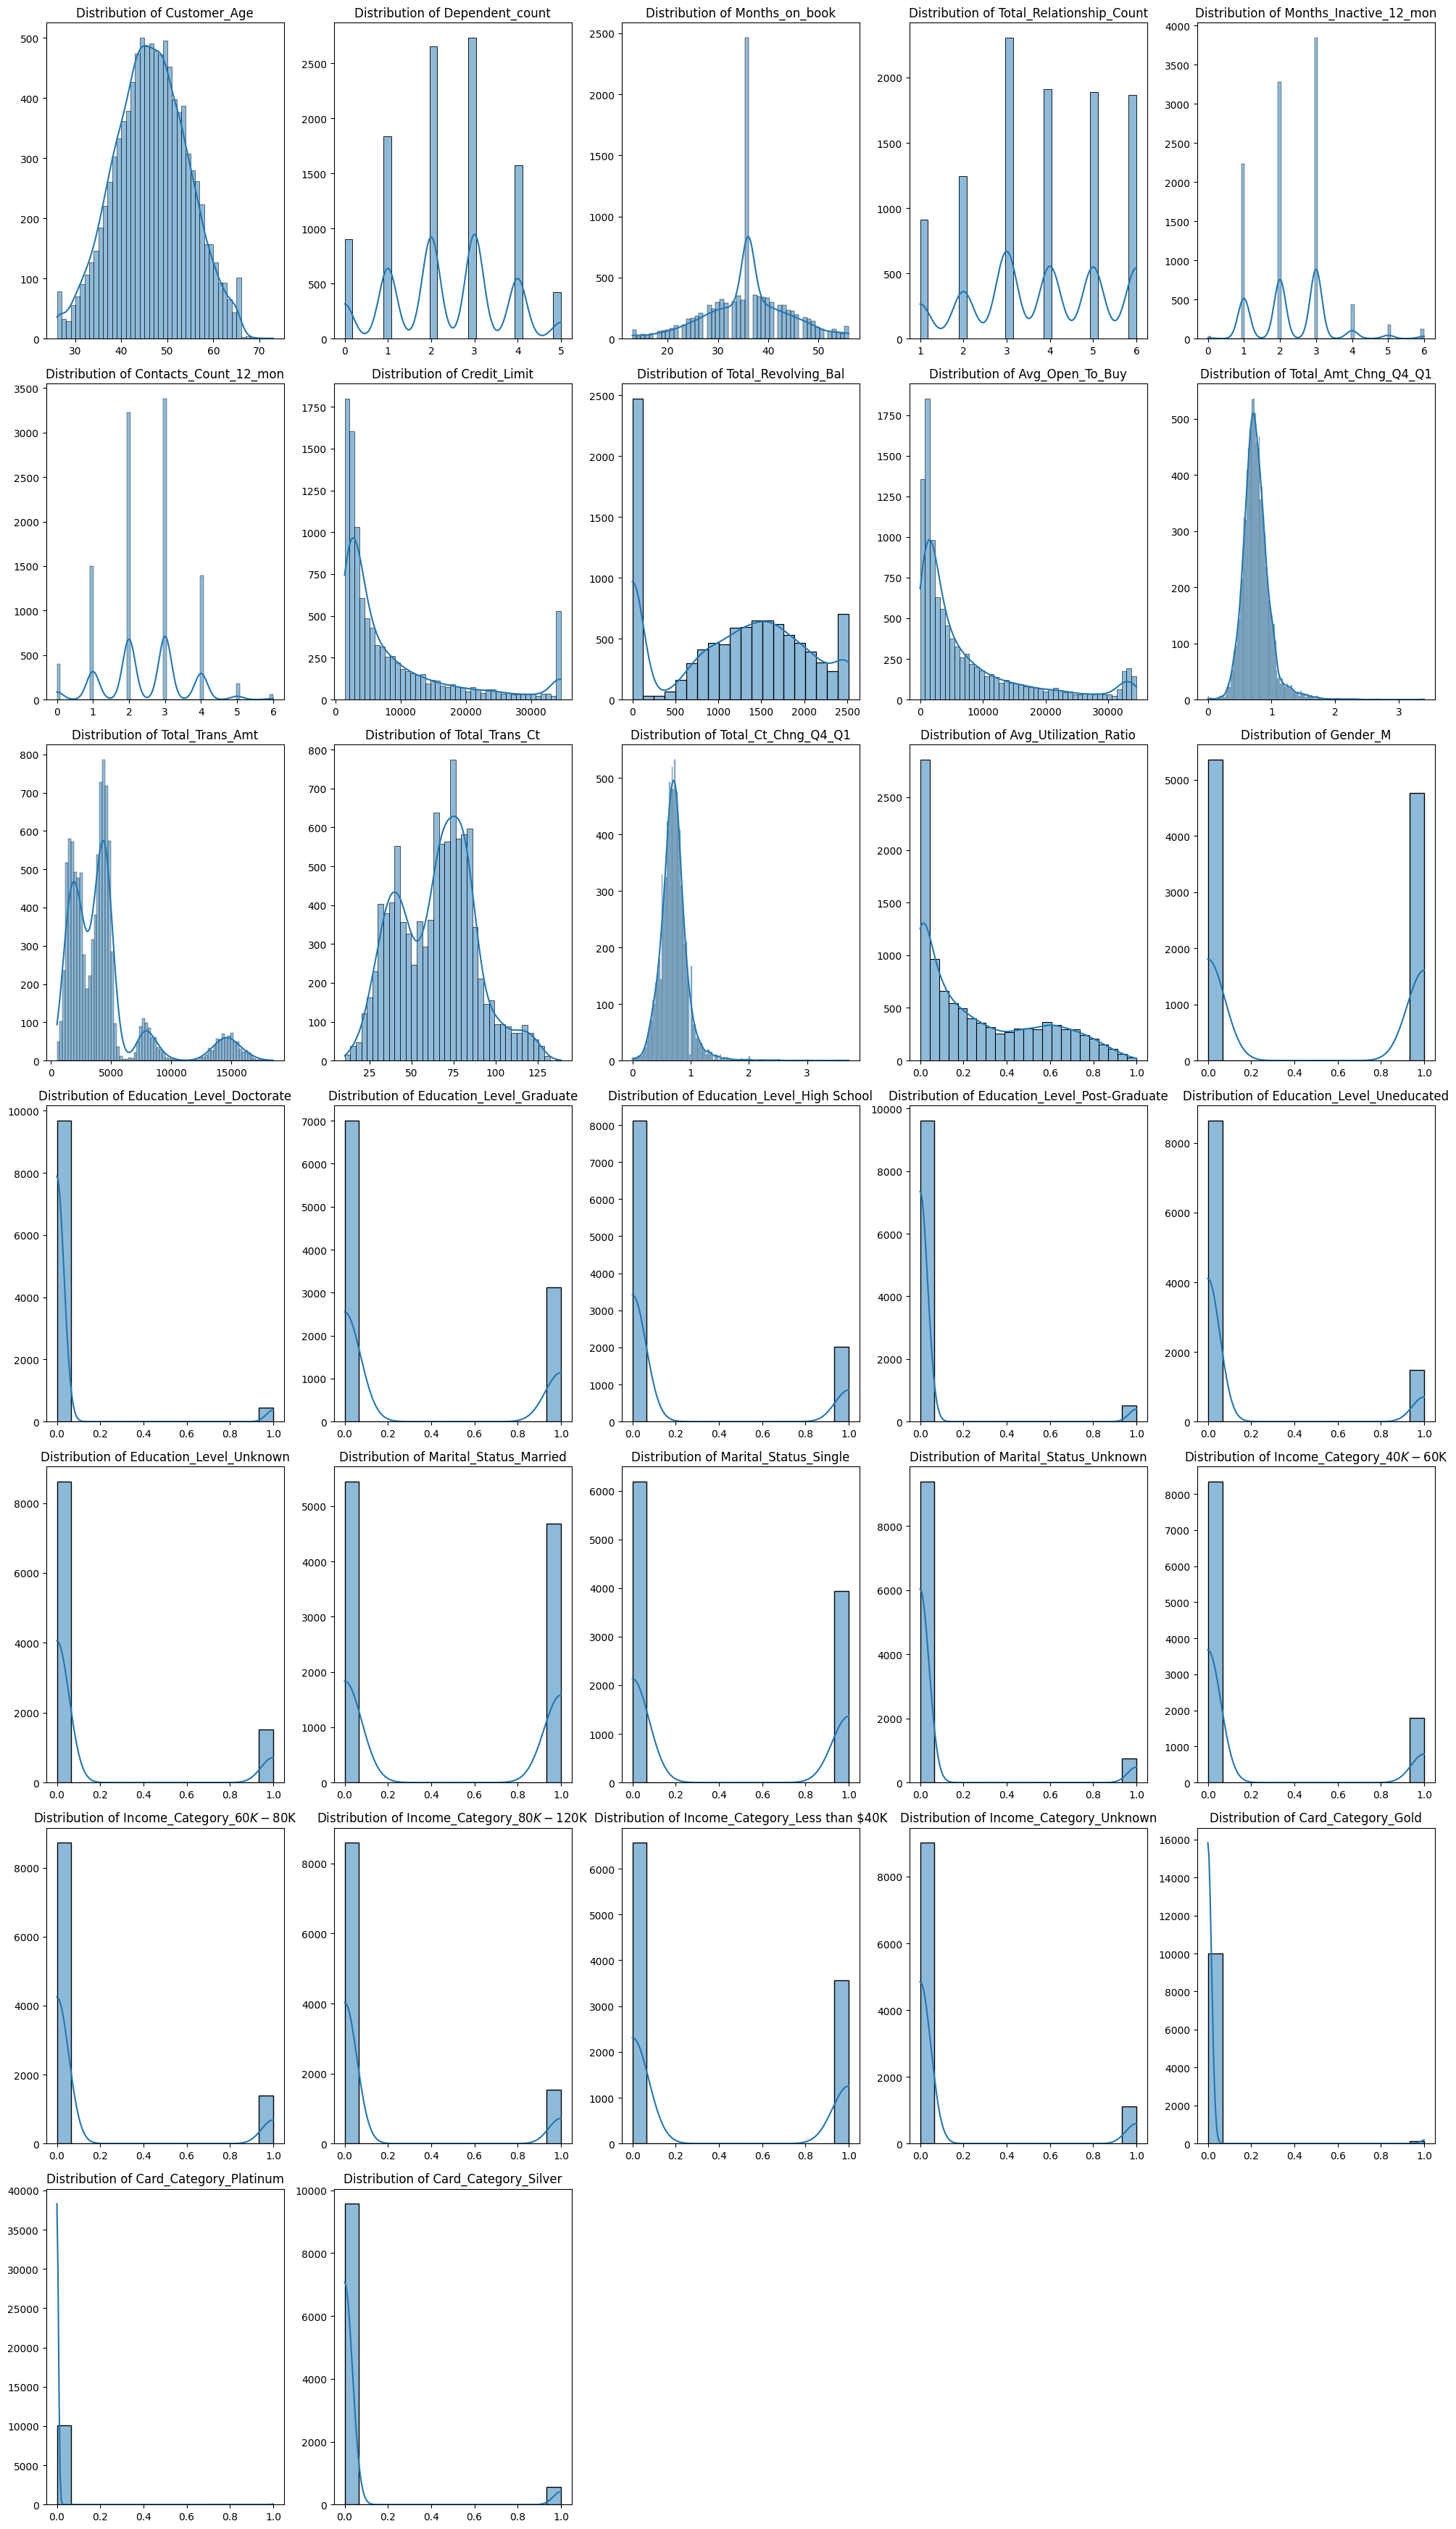

In [59]:
num_columns = df_encoded.shape[1]
num_rows = (num_columns + 4) // 5

plt.figure(figsize=(20, 5 * num_rows))

for i, column in enumerate(df_encoded.columns):
    plt.subplot(num_rows, 5, i + 1)
    sns.histplot(data=df_encoded, x=column, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

## Correlation matrix

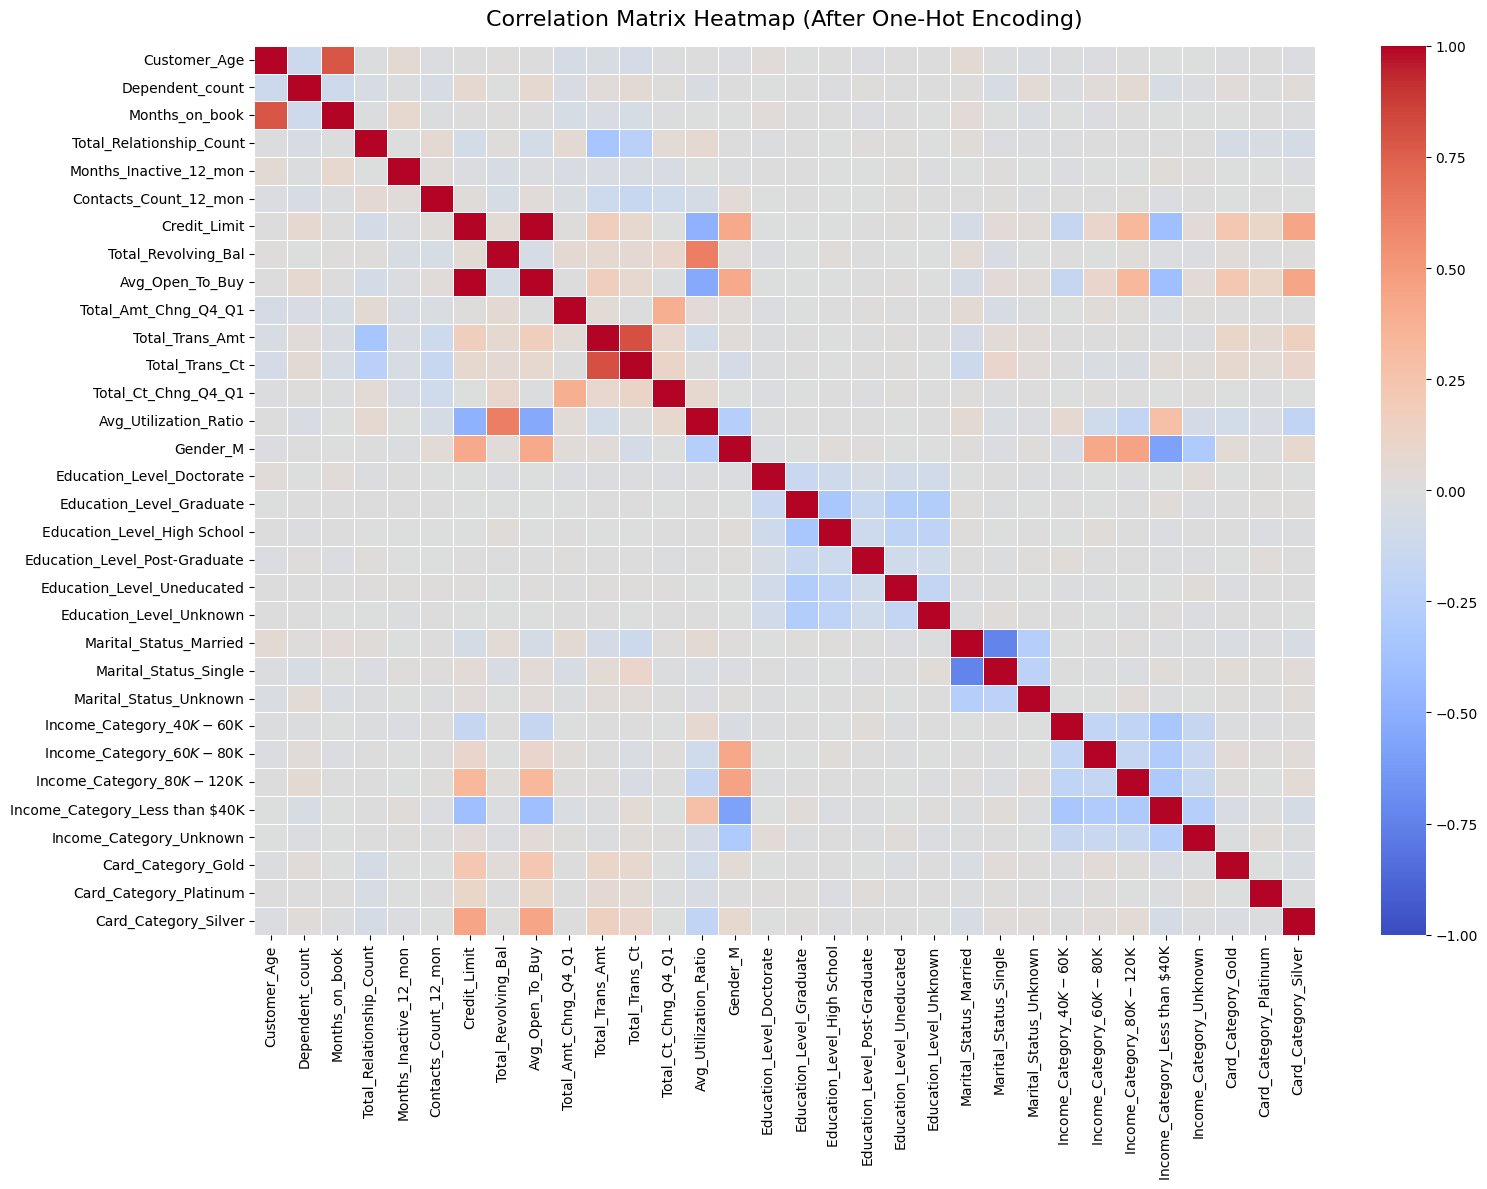

In [60]:
corr_matrix = df_encoded.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Correlation Matrix Heatmap (After One-Hot Encoding)", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [61]:
high_corr_series = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack()
high_corr_series = high_corr_series[high_corr_series > 0.6].sort_values(
    ascending=False
)

print("Highly correlated pairs (absolute correlation > 0.6):")
print(high_corr_series)

Highly correlated pairs (absolute correlation > 0.6):
Credit_Limit         Avg_Open_To_Buy          0.995981
Total_Trans_Amt      Total_Trans_Ct           0.807192
Customer_Age         Months_on_book           0.788912
Total_Revolving_Bal  Avg_Utilization_Ratio    0.624022
dtype: float64


Credit_limit and Avg_Open_To_Buy have a very strong correlation (0.99) suggesting that customers with higher credit limits almost always have additional amount to buy more things. Customers making higher value of transcation also tend to make higher total tanscations (0.81). Older customers tend to be for longer times with their bank (0.79). We will remove Avg_Open_To_Buy and Total_Trans_Amt from our clustering.

In [62]:
df_encoded = df_encoded.drop(columns=['Avg_Open_To_Buy','Total_Trans_Amt'])

## Find outliers using the median absolute deviation (MAD)
MAD is more robust than Z-score as it uses the median instead of mean to find outliers.

In [63]:
def is_mad_outlier(column, threshold=3.5):
    median = column.median()
    mad = (column - median).abs().median()
    if mad == 0:
        return pd.Series(False, index=column.index)
    mod_z_score = 0.6745 * (column - median) / mad
    return mod_z_score.abs() > threshold

outlier_mask = df_encoded.apply(is_mad_outlier)

outlier_rows = df_encoded[outlier_mask.any(axis=1)]
print("Rows with at least one outlier:")
print(outlier_rows)
print("Total outliers:",len(outlier_rows))

Rows with at least one outlier:
       Customer_Age  Dependent_count  Months_on_book  \
0                45                3              39   
1                49                5              44   
2                51                3              36   
3                40                4              34   
4                40                3              21   
...             ...              ...             ...   
10103            51                1              36   
10104            51                3              36   
10110            56                1              49   
10112            33                2              20   
10114            29                0              15   

       Total_Relationship_Count  Months_Inactive_12_mon  \
0                             5                       1   
1                             6                       1   
2                             4                       1   
3                             3                       4   


1872 outliers were found using the MAD technique. This is a substantial amount of the dataset (~18%). We will not remove them but rather use a more robust algorithms for outliers (e.g., DBSCAN) than K-means or Hierarchical clustering.

## K-means clustering

Let's create a function to run K-Means for a range of clusters and calculate both Silhouette and Davies-Bouldin scores.

In [65]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

def evaluate_kmeans_clusters(data, min_k=2, max_k=10):
    results = []
    for k in range(min_k, max_k + 1):
        kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
        labels = kmeans.fit_predict(data)

        silhouette_avg = silhouette_score(data, labels)
        davies_bouldin_avg = davies_bouldin_score(data, labels)

        results.append({
            'n_clusters': k,
            'silhouette_score': silhouette_avg,
            'davies_bouldin_index': davies_bouldin_avg
        })
    return pd.DataFrame(results)

k_means_evaluation_df = evaluate_kmeans_clusters(df_scaled, min_k=2, max_k=10)

print("K-Means Clustering Evaluation:")
display(k_means_evaluation_df)

K-Means Clustering Evaluation:


,n_clusters,silhouette_score,davies_bouldin_index
0,2,0.082682,3.470954
1,3,0.080498,3.292869
2,4,0.099925,2.708023
3,5,0.116685,2.637884
4,6,0.123261,2.329150
5,7,0.125382,2.243934
6,8,0.100568,2.397628
7,9,0.085286,2.297293
8,10,0.103730,2.366115


### DBSCAN Clustering Evaluation


In [93]:
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

def evaluate_dbscan_clusters(data, eps_values, min_samples):
    results = []
    total_samples = len(data)
    for eps_val in eps_values:
        dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
        labels = dbscan.fit_predict(data)

        num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        num_noise_points = list(labels).count(-1)

        if num_clusters < 2 or len(set(labels)) == 1 or (num_noise_points / total_samples) > 0.2:
            silhouette_avg = np.nan
            davies_bouldin_avg = np.nan
            reason = []
            if num_clusters < 2:
                reason.append("too few clusters")
            if (num_noise_points / total_samples) > 0.2:
                reason.append(f"excessive noise points ({num_noise_points}/{total_samples} samples, >20%)")
            if not reason:
                 reason.append("not enough data points for meaningful cluster evaluation")

            print(f"DBSCAN with eps={eps_val}, min_samples={min_samples}: Skipping score calculation (Clusters: {num_clusters}, Noise points: {num_noise_points}). Reason: {'; '.join(reason)}.")
        else:
            core_samples_mask = labels != -1
            if np.sum(core_samples_mask) > 1:
                silhouette_avg = silhouette_score(data[core_samples_mask], labels[core_samples_mask])
                davies_bouldin_avg = davies_bouldin_score(data[core_samples_mask], labels[core_samples_mask])
            else:
                silhouette_avg = np.nan
                davies_bouldin_avg = np.nan
                print(f"DBSCAN with eps={eps_val}, min_samples={min_samples}: Not enough non-noise points for metrics. Skipping score calculation.")

        results.append({
            'eps': eps_val,
            'min_samples': min_samples,
            'num_clusters': num_clusters,
            'num_noise_points': num_noise_points,
            'silhouette_score': silhouette_avg,
            'davies_bouldin_index': davies_bouldin_avg
        })
    return pd.DataFrame(results)

eps_values_to_test = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4, 4.5, 5]
fixed_min_samples = df_scaled.shape[1] * 2

dbscan_evaluation_df = evaluate_dbscan_clusters(df_scaled, eps_values_to_test, fixed_min_samples)

print("DBSCAN Clustering Evaluation:")
display(dbscan_evaluation_df)

DBSCAN with eps=0.5, min_samples=60: Skipping score calculation (Clusters: 0, Noise points: 10127). Reason: too few clusters; excessive noise points (10127/10127 samples, >20%).
DBSCAN with eps=1.0, min_samples=60: Skipping score calculation (Clusters: 0, Noise points: 10127). Reason: too few clusters; excessive noise points (10127/10127 samples, >20%).
DBSCAN with eps=1.5, min_samples=60: Skipping score calculation (Clusters: 0, Noise points: 10127). Reason: too few clusters; excessive noise points (10127/10127 samples, >20%).
DBSCAN with eps=2.0, min_samples=60: Skipping score calculation (Clusters: 0, Noise points: 10127). Reason: too few clusters; excessive noise points (10127/10127 samples, >20%).
DBSCAN with eps=2.5, min_samples=60: Skipping score calculation (Clusters: 0, Noise points: 10127). Reason: too few clusters; excessive noise points (10127/10127 samples, >20%).
DBSCAN with eps=3.0, min_samples=60: Skipping score calculation (Clusters: 6, Noise points: 8471). Reason: exc

,eps,min_samples,num_clusters,num_noise_points,silhouette_score,davies_bouldin_index
0,0.5,60,0,10127,NaN,NaN
1,1.0,60,0,10127,NaN,NaN
2,1.5,60,0,10127,NaN,NaN
3,2.0,60,0,10127,NaN,NaN
4,2.5,60,0,10127,NaN,NaN
5,3.0,60,6,8471,NaN,NaN
6,3.5,60,6,5214,NaN,NaN
7,4.0,60,4,2249,NaN,NaN
8,4.5,60,3,1202,0.14555,1.861527
9,5.0,60,1,366,NaN,NaN


Let's visualize the Silhouette and Davies-Bouldin scores for DBSCAN (if calculated).

### Agglomerative Clustering Evaluation

In [69]:
from sklearn.cluster import AgglomerativeClustering

def evaluate_agglomerative_clusters(data, min_k=2, max_k=10, linkage='ward'):
    results = []
    for k in range(min_k, max_k + 1):
        agg_cluster = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = agg_cluster.fit_predict(data)

        silhouette_avg = silhouette_score(data, labels)

        davies_bouldin_avg = davies_bouldin_score(data, labels)

        results.append({
            'n_clusters': k,
            'linkage': linkage,
            'silhouette_score': silhouette_avg,
            'davies_bouldin_index': davies_bouldin_avg
        })
    return pd.DataFrame(results)

agg_evaluation_df = evaluate_agglomerative_clusters(df_scaled, min_k=2, max_k=10)

print("Agglomerative Clustering Evaluation:")
display(agg_evaluation_df)

Agglomerative Clustering Evaluation:


,n_clusters,linkage,silhouette_score,davies_bouldin_index
0,2,ward,0.076529,4.004635
1,3,ward,0.088740,3.268122
2,4,ward,0.064637,2.932196
3,5,ward,0.074701,2.474632
4,6,ward,0.079759,2.100733
5,7,ward,0.093035,2.033401
6,8,ward,0.089785,2.235660
7,9,ward,0.101464,2.074631
8,10,ward,0.114110,1.996320


### Summary of clustering results

In [94]:
best_kmeans_silhouette = k_means_evaluation_df.loc[k_means_evaluation_df['silhouette_score'].idxmax()]
best_kmeans_dbi = k_means_evaluation_df.loc[k_means_evaluation_df['davies_bouldin_index'].idxmin()]

best_dbscan_silhouette = dbscan_evaluation_df.loc[dbscan_evaluation_df['silhouette_score'].idxmax()] if not dbscan_evaluation_df['silhouette_score'].isnull().all() else None
best_dbscan_dbi = dbscan_evaluation_df.loc[dbscan_evaluation_df['davies_bouldin_index'].idxmin()] if not dbscan_evaluation_df['davies_bouldin_index'].isnull().all() else None

best_agg_silhouette = agg_evaluation_df.loc[agg_evaluation_df['silhouette_score'].idxmax()]
best_agg_dbi = agg_evaluation_df.loc[agg_evaluation_df['davies_bouldin_index'].idxmin()]

print("--- Best Clustering Metrics Comparison ---")

print("\nK-Means:")
print(f"  Best Silhouette Score ({best_kmeans_silhouette['n_clusters']} clusters): {best_kmeans_silhouette['silhouette_score']:.4f}")
print(f"  Best Davies-Bouldin Index ({best_kmeans_dbi['n_clusters']} clusters): {best_kmeans_dbi['davies_bouldin_index']:.4f}")

print("\nDBSCAN:")
if best_dbscan_silhouette is not None:
    print(f"  Best Silhouette Score (eps={best_dbscan_silhouette['eps']}, min_samples={best_dbscan_silhouette['min_samples']}): {best_dbscan_silhouette['silhouette_score']:.4f}")
    print(f"  Best Davies-Bouldin Index (eps={best_dbscan_dbi['eps']}, min_samples={best_dbscan_dbi['min_samples']}): {best_dbscan_dbi['davies_bouldin_index']:.4f}")
else:
    print("  No valid DBSCAN silhouette or DBI scores could be calculated.")

print("\nAgglomerative Clustering:")
print(f"  Best Silhouette Score ({best_agg_silhouette['n_clusters']} clusters): {best_agg_silhouette['silhouette_score']:.4f}")
print(f"  Best Davies-Bouldin Index ({best_agg_dbi['n_clusters']} clusters): {best_agg_dbi['davies_bouldin_index']:.4f}")

--- Best Clustering Metrics Comparison ---

K-Means:
  Best Silhouette Score (7.0 clusters): 0.1254
  Best Davies-Bouldin Index (7.0 clusters): 2.2439

DBSCAN:
  Best Silhouette Score (eps=4.5, min_samples=60.0): 0.1456
  Best Davies-Bouldin Index (eps=4.5, min_samples=60.0): 1.8615

Agglomerative Clustering:
  Best Silhouette Score (10 clusters): 0.1141
  Best Davies-Bouldin Index (10 clusters): 1.9963


As expected, due to high number of outliers, DBSCAN handles them better (Silhouette 0.1456, Davies-Bouldin Index 1.86). However, for this setting (eps = 4.5, min_samples = 60), However DBSCAN classified ~10% of the dataset (1202 samples) as noise.

### t-SNE Visualization of DBSCAN Clusters


DBSCAN with eps=4.5, min_samples=60 found 3 clusters (excluding noise points).
Number of noise points (labeled -1): 1202


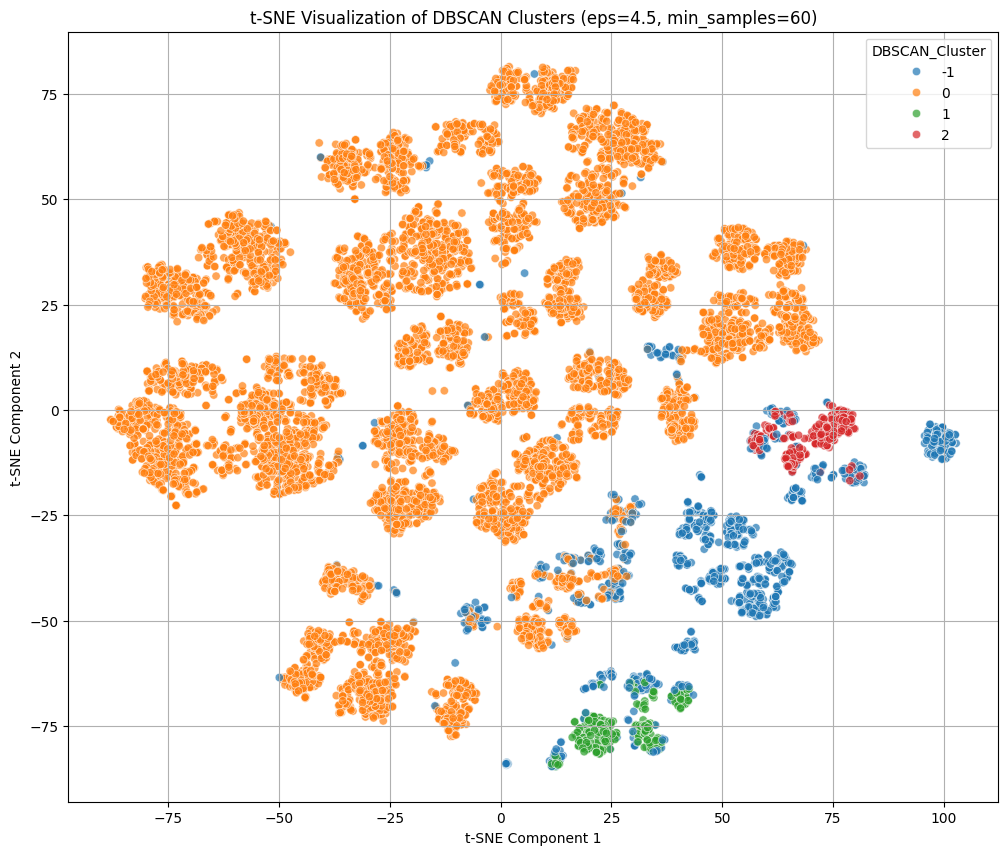

In [95]:
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN

chosen_eps = 4.5
chosen_min_samples = fixed_min_samples

dbsc_model_for_viz = DBSCAN(eps=chosen_eps, min_samples=chosen_min_samples)
dbsc_labels_for_viz = dbsc_model_for_viz.fit_predict(df_scaled)

print(f"DBSCAN with eps={chosen_eps}, min_samples={chosen_min_samples} found {len(set(dbsc_labels_for_viz)) - (1 if -1 in dbsc_labels_for_viz else 0)} clusters (excluding noise points).")
print(f"Number of noise points (labeled -1): {list(dbsc_labels_for_viz).count(-1)}")

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(df_scaled)

tsne_df = pd.DataFrame(data=tsne_results, columns=['tsne_1', 'tsne_2'])
tsne_df['DBSCAN_Cluster'] = dbsc_labels_for_viz

plt.figure(figsize=(12, 10))
sns.scatterplot(
    x='tsne_1',
    y='tsne_2',
    hue='DBSCAN_Cluster',
    palette='tab10' if len(tsne_df['DBSCAN_Cluster'].unique()) <= 10 else 'viridis',
    data=tsne_df,
    legend='full',
    alpha=0.7
)
plt.title(f't-SNE Visualization of DBSCAN Clusters (eps={chosen_eps}, min_samples={chosen_min_samples})')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

### UMAP Visualization of DBSCAN Clusters

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


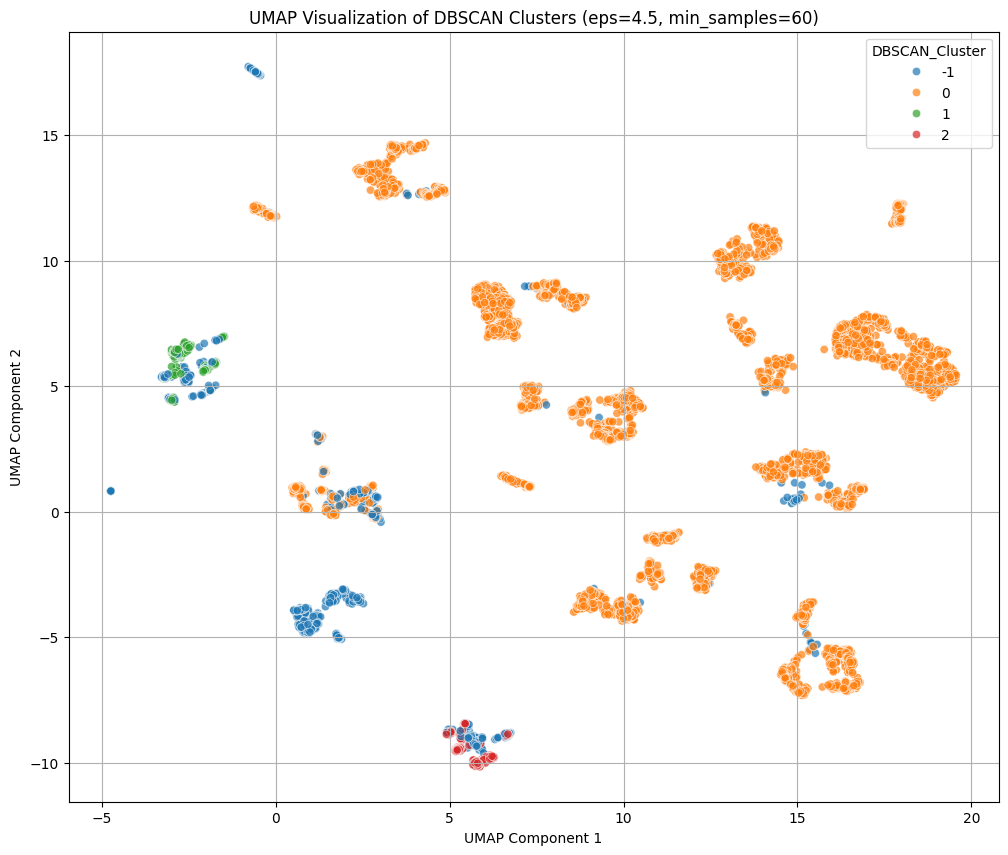

In [96]:
import umap

reducer = umap.UMAP(random_state=42)
umap_results = reducer.fit_transform(df_scaled)

umap_df = pd.DataFrame(data=umap_results, columns=['umap_1', 'umap_2'])
umap_df['DBSCAN_Cluster'] = dbsc_labels_for_viz

plt.figure(figsize=(12, 10))
sns.scatterplot(
    x='umap_1',
    y='umap_2',
    hue='DBSCAN_Cluster',
    palette='tab10' if len(umap_df['DBSCAN_Cluster'].unique()) <= 10 else 'viridis',
    data=umap_df,
    legend='full',
    alpha=0.7
)
plt.title(f'UMAP Visualization of DBSCAN Clusters (eps={chosen_eps}, min_samples={chosen_min_samples})')
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.grid(True)
plt.show()

Both t-sne and UMAP show distinct clusters with half fo the samples classified as noise by DBSCAN, the rest tend to cluster together as in DBSCAN.

## Interpret the centroids in each cluster

To interpret the clusters, we will analyze the centroids (mean values) of each feature within each cluster. Noise points (labeled -1) will be excluded from this analysis.

In [97]:
df_clustered = df_encoded.copy()
df_clustered['DBSCAN_Cluster'] = dbsc_labels_for_viz

clustered_data = df_clustered[df_clustered['DBSCAN_Cluster'] != -1]
cluster_centroids = clustered_data.groupby('DBSCAN_Cluster').mean()

print("Cluster Centroids (Mean Feature Values per Cluster):")
display(cluster_centroids)

Cluster Centroids (Mean Feature Values per Cluster):


,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Total_Amt_Chng_Q4_Q1,Total_Trans_Ct,...,Marital_Status_Single,Marital_Status_Unknown,Income_Category_$40K - $60K,Income_Category_$60K - $80K,Income_Category_$80K - $120K,Income_Category_Less than $40K,Income_Category_Unknown,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver
DBSCAN_Cluster,,,,,,,,,,,,,,,,,,,,,
0,46.353360,2.338883,35.959102,3.852696,2.340934,2.460731,7255.733442,1159.423453,0.754500,64.363132,...,0.394378,0.052720,0.176378,0.134274,0.143081,0.370612,0.106527,0.0,0.0,0.0
1,45.487879,2.403030,35.345455,3.909091,2.303030,2.324242,5518.005455,1229.906061,0.762942,64.903030,...,0.330303,0.003030,0.236364,0.154545,0.069697,0.454545,0.042424,0.0,0.0,0.0
2,47.212418,2.310458,36.679739,3.709150,2.303922,2.437908,5746.332026,992.486928,0.723150,64.428105,...,0.437908,0.009804,0.183007,0.081699,0.104575,0.477124,0.071895,0.0,0.0,0.0


To further understand the characteristics of each cluster, we can compare their centroids (mean values) to the global mean of each feature across the entire dataset. This will highlight which features are above or below average for each cluster.

In [98]:
global_mean = df_encoded.mean()

global_mean_df = pd.DataFrame(global_mean).T
global_mean_df.index = ['Global_Mean']

comparison_df = pd.concat([global_mean_df, cluster_centroids])

print("Comparison of Cluster Centroids with Global Mean:")
display(comparison_df.T.style.background_gradient(cmap='RdYlGn', axis=1))

Comparison of Cluster Centroids with Global Mean:


,Global_Mean,0,1,2
Customer_Age,46.325960,46.353360,45.487879,47.212418
Dependent_count,2.346203,2.338883,2.403030,2.310458
Months_on_book,35.928409,35.959102,35.345455,36.679739
Total_Relationship_Count,3.812580,3.852696,3.909091,3.709150
Months_Inactive_12_mon,2.341167,2.340934,2.303030,2.303922
Contacts_Count_12_mon,2.455317,2.460731,2.324242,2.437908
Credit_Limit,8631.953698,7255.733442,5518.005455,5746.332026
Total_Revolving_Bal,1162.814061,1159.423453,1229.906061,992.486928
Total_Amt_Chng_Q4_Q1,0.759941,0.754500,0.762942,0.723150
Total_Trans_Ct,64.858695,64.363132,64.903030,64.428105


The table above shows the global mean for each feature and the mean for each DBSCAN cluster. By comparing these values, you can identify:

**Higher than average values:** Indicate features that are characteristic of that particular cluster and are more prominent in that segment of customers.

We can clearly see that most of the working population has income between 60K-120K (cluster 0), the younger and older populations tend to earn less (clusters 1 & 2, respectively).